<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Fraction of genes and of low-density "other" uRNA explained by technical noise (control probes / inferred noise).
> - **Manuscript panels:** Fig. 3A
> - **Inputs:** `data_with_source_score.zarr` of every dataset/segmentation
> - **Outputs:** Noise proportion barplots and strip plots
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Aim of the notebook

Recompute the noise proportion metrics (`genes_prop_over_noise` / `noise_RNA_proportion` used in `1_summary_metrics_roi_analysis_revisions.ipynb`), but restrict the noise model to **"other unassigned RNA"** instead of all transcripts.

"Other unassigned RNA" is defined as transcripts where:
- `overlaps_cell == False` (not captured by segmentation)
- `extracellular == True` (classified as uRNA)
- `enrichment_class != "High Density"` (excluding dense extracellular clusters, which more likely reflect real extracellular structures/diffusion than background noise)

For each dataset, we load `data_with_segfree_2.zarr` (saved right after `tl.density_similarity`, i.e. after `enrichment_class` is computed but before the global noise model is fit), restrict to this "other" population, and refit the per-gene Poisson noise model (same approach as `tl.quantify_overexpression`) using only those transcripts. From this we compute:
- **proportion of genes explained by noise**: fraction of (non-control) genes whose "other RNA" counts are not significantly above the control-probe noise baseline
- **proportion of "other" uRNA explained by noise**: fraction of "other RNA" transcripts belonging to those noise genes

# Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import spatialdata as sd
from scipy.stats import poisson
from statsmodels.stats.multitest import multipletests
import troutpy

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
base_dir = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/"
saving_path = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/figures/other_rna_noise/"
os.makedirs(saving_path, exist_ok=True)

# Segmentation methods: default segmentation lives directly in `rois`,
# the other two segmentation methods each have their own root folder.
segmentations = ["rois", "rois_proseg", "rois_segger"]

max_p_val_noise = 0.05

# Compute per-gene noise significance restricted to "other unassigned RNA"

In [3]:
def compute_other_rna_noise_stats(transcripts, max_p_val_noise=0.05):
    """Fit the Poisson noise model on 'other unassigned RNA' only.

    Mirrors troutpy.tl.quantify_overexpression's Poisson noise model (gene counts
    vs. control-probe baseline), but the input population is restricted to
    transcripts that are extracellular, don't overlap a segmented cell, and are
    not part of a 'High Density' extracellular cluster.

    Returns (stats, gene_info): the aggregate stats dict, and the per-gene table
    (count, p_val_noise, is_control, fdr_noise) the stats were derived from.
    """
    n_total_transcripts = len(transcripts)

    other = transcripts.loc[
        (~transcripts["overlaps_cell"])
        & transcripts["extracellular"]
        & (transcripts["enrichment_class"] != "High Density")
    ]

    # "gene" is categorical, so value_counts() would otherwise include every
    # panel gene (count 0) even if it never occurs in this subset
    gene_counts = other["gene"].value_counts()
    gene_counts = gene_counts[gene_counts > 0]

    # control_probe is stored as real bool in some segmentation outputs (e.g. rois,
    # rois_segger) but as string[pyarrow] "True"/"False" in others (e.g. rois_proseg)
    control_probe = other["control_probe"]
    if control_probe.dtype != bool:
        control_probe = control_probe.astype(str).str.strip().str.lower().isin(["true", "1"])
    is_control_map = dict(zip(other["gene"], control_probe))

    # Noise baseline (lambda) from control probe counts within the "other RNA" subset
    control_obs = [gene_counts[g] for g in gene_counts.index if is_control_map.get(g, True)]
    lambda_noise = np.mean(control_obs) if control_obs else 1e-6

    gene_info = pd.DataFrame({"count": gene_counts})
    gene_info["p_val_noise"] = poisson.sf(gene_info["count"] - 1, lambda_noise)
    gene_info["is_control"] = gene_info.index.map(is_control_map).astype(bool)
    _, gene_info["fdr_noise"], _, _ = multipletests(gene_info["p_val_noise"], method="fdr_bh")

    real_genes = gene_info.loc[~gene_info["is_control"]]
    non_noise_genes = real_genes.index[real_genes["p_val_noise"] < max_p_val_noise]

    if real_genes.shape[0] == 0:
        genes_noise_prop = np.nan
        urna_noise_prop = np.nan
    else:
        genes_noise_prop = 1 - len(non_noise_genes) / real_genes.shape[0]
        urna_noise_prop = 1 - other["gene"].isin(non_noise_genes).mean()

    stats = {
        "n_total_transcripts": n_total_transcripts,
        "n_other_transcripts": len(other),
        "n_other_genes": real_genes.shape[0],
        "lambda_noise": lambda_noise,
        "proportion_of_total_rna_other": (len(other) / n_total_transcripts) if n_total_transcripts else np.nan,
        "proportion_of_other_genes_noise": genes_noise_prop,
        "proportion_of_other_urna_noise": urna_noise_prop,
    }
    return stats, gene_info

# Run across all datasets and segmentation methods

In [4]:
required_cols = ["gene", "overlaps_cell", "extracellular", "enrichment_class", "control_probe"]

records = []
rois_gene_info = {}  # per-sample gene-level counts for the default segmentation ("rois"), used below

for seg in segmentations:
    root_dir = os.path.join(base_dir, seg)

    for subfolder in sorted(f.path for f in os.scandir(root_dir) if f.is_dir()):
        sample = os.path.basename(subfolder)
        zarr_path = os.path.join(subfolder, "data_with_segfree_2.zarr")

        if not os.path.isdir(zarr_path):
            continue

        try:
            # Only load the points element - images/labels/shapes/table aren't needed here
            sdata = sd.read_zarr(zarr_path, selection=("points",))
            transcripts = sdata.points["transcripts"][required_cols].compute()
        except Exception as e:
            print(f"[{seg}/{sample}] Skipped - failed to load: {e}")
            continue

        stats, gene_info = compute_other_rna_noise_stats(transcripts, max_p_val_noise=max_p_val_noise)
        stats["segmentation"] = seg
        stats["sample"] = sample
        records.append(stats)

        if seg == "rois":
            rois_gene_info[sample] = gene_info

        print(
            f"[{seg}/{sample}] n_other={stats['n_other_transcripts']}, "
            f"other_of_total={stats['proportion_of_total_rna_other']:.3f}, "
            f"genes_noise={stats['proportion_of_other_genes_noise']:.2f}, "
            f"urna_noise={stats['proportion_of_other_urna_noise']:.2f}"
        )

other_rna_noise_df = pd.DataFrame(records).set_index(["segmentation", "sample"])
other_rna_noise_df.to_csv(os.path.join(saving_path, "other_rna_noise_stats.csv"))
other_rna_noise_df

[rois/atera_hsbreast] n_other=1121169, other_of_total=0.020, genes_noise=0.17, urna_noise=0.01


[rois/cosmx_hgsoc] n_other=17096, other_of_total=0.068, genes_noise=0.69, urna_noise=0.46


[rois/cosmx_melanoma] n_other=6149, other_of_total=0.002, genes_noise=0.67, urna_noise=0.25


[rois/cosmx_mousebrain] n_other=3587901, other_of_total=0.189, genes_noise=0.09, urna_noise=0.00


[rois/cosmx_stomach] n_other=12026, other_of_total=0.014, genes_noise=0.73, urna_noise=0.43


...

[rois_segger/xenium_mscolon_5k] n_other=369201, other_of_total=0.030, genes_noise=0.11, urna_noise=0.01


[rois_segger/xenium_opsc_5k] n_other=2594109, other_of_total=0.041, genes_noise=0.11, urna_noise=0.00


[rois_segger/xenium_opsc_v1] n_other=379092, other_of_total=0.017, genes_noise=0.92, urna_noise=0.75


[rois_segger/xenium_rcc] n_other=294028, other_of_total=0.040, genes_noise=0.86, urna_noise=0.66


n_total_transcripts  n_other_transcripts  \
segmentation sample                                                         
rois         atera_hsbreast                 55991728              1121169   
             cosmx_hgsoc                      251217                17096   
             cosmx_melanoma                  3043815                 6149   
             cosmx_mousebrain               19013669              3587901   
             cosmx_stomach                    853995                12026   
             merscope_hsbrain                 305050                 1511   
             merscope_hsuterine              6656782                34276   
             xenium_hsfemur                  1347715                94352   
             xenium_hsheart                  2451466                72086   
             xenium_hsprostate               2184955               163233   
             xenium_hsputamen                 744458               215152   
             xenium_hsskin_5k                4644030               186972   
             xenium_msbrain_300              8906974              1924003   
             xenium_msbrain_5k              23790756              4544998   
             xenium_mscolon_5k              12204167               284484   
             xenium_opsc_5k                 63989200              1510163   
             xenium_opsc_v1                 21912652               200762   
rois_proseg  atera_hsbreast                 55991728              1460187   
             cosmx_hgsoc                      251217                22154   
             cosmx_melanoma                  3043815                 4194   
             cosmx_mousebrain               19013669              2609416   
             cosmx_pancreas                  3378688               459361   
             cosmx_stomach                    853995                16244   
             merscope_hsbrain                 305050                 9041   
             merscope_hsuterine              6656782                  986   
             xenium_hsfemur                  1347715               166299   
             xenium_hsheart                  2451466               144891   
             xenium_hsprostate               2184955               135936   
             xenium_hsputamen                 744458               174489   
             xenium_hsskin_5k                4644030               130056   
             xenium_msbrain_300              8906974               912833   
             xenium_msbrain_5k              23790756              3678365   
             xenium_mscolon_5k              12204167               114876   
             xenium_opsc_5k                 63989200              1286161   
             xenium_opsc_v1                 21912652               139352   
rois_segger  atera_hsbreast                 55991728              6461768   
             merscope_hsbrain                 305050                 1633   
             merscope_hsuterine              6656782                17582   
             xenium_hsfemur                  1347715               112822   
             xenium_hsheart                  2451466                48020   
             xenium_hsprostate               2184955               229317   
             xenium_hsputamen                 744458                19954   
             xenium_hsskin_5k                4644030               264386   
             xenium_msbrain_300              8906974               449187   
             xenium_msbrain_5k              23790756              4754177   
             xenium_mscolon_5k              12204167               369201   
             xenium_opsc_5k                 63989200              2594109   
             xenium_opsc_v1                 21912652               379092   
             xenium_rcc                      7272244               294028   

                                 n_other_genes  lambda_noise  \
segmentation sample                      

# Visualizations

## Shared plot setup

A single color scheme and a single sample order, reused by every plot below so rows line up and are directly comparable across metrics and across segmentation methods.

In [5]:
# Matplotlib output editable in Illustrator (fonts kept as text, not outlined paths)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# Noise is the thing we want the reader's eye drawn to, so it gets a single strong
# accent color; everything else that isn't noise is a neutral gray (an "emphasis"
# scheme, not a 2-hue categorical split - troutpy's own palette slot for this turned
# out to be a low-contrast pale yellow, so this uses a validated, high-contrast red
# instead). Control-probe vs. gene below uses a separate, CVD-validated categorical
# pair, since that plot's job is telling the two groups apart, not flagging one.
noise_color = "#e34948"
other_color = "#BCBCBC"
gene_color = "#2a78d6"
control_color = "#eb6834"

# One sample order shared by every plot below (the context plot, the gene-noise
# plots, and all 3 segmentation methods), so the same row always means the same
# sample no matter which figure you're looking at
sample_order = (
    other_rna_noise_df.reset_index()
    .groupby("sample")["proportion_of_total_rna_other"]
    .mean()
    .sort_values(ascending=True)
    .index.tolist()
)

## Context: how much of total RNA is "other" uRNA, and how much of that is noise

One plot per segmentation method. Each bar's full length is the % of **all** transcripts in the sample (intracellular + extracellular) that fall into the "other unassigned RNA" pool - this contextualizes how big that pool even is before asking what fraction of it is noise.

The colored segment starts at 0 (rather than stacking on top) so its length - the % of *total* RNA attributable to noise genes - shares a common baseline and is directly comparable across samples and across segmentation methods, which a segment floating on top of a variable-length base would not be.

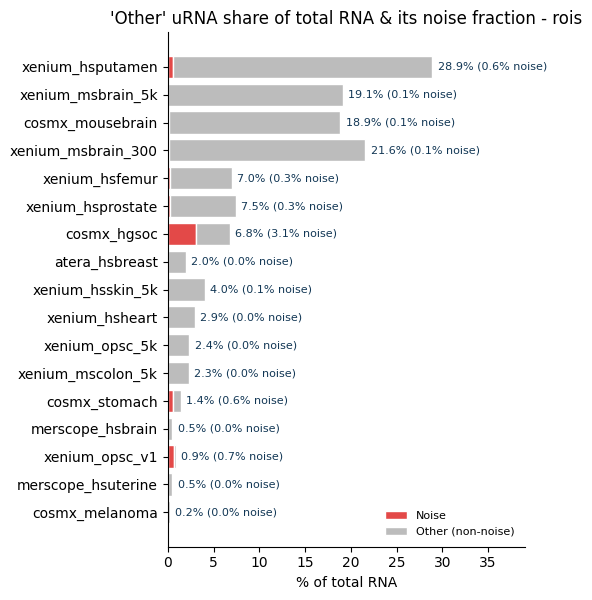

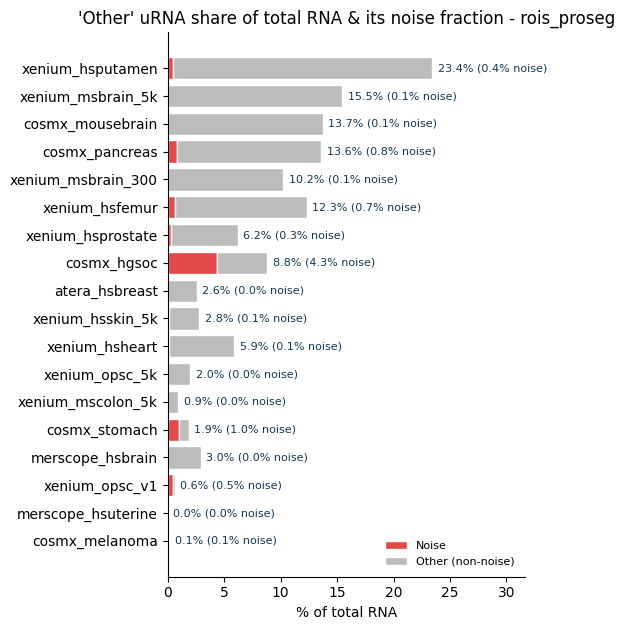

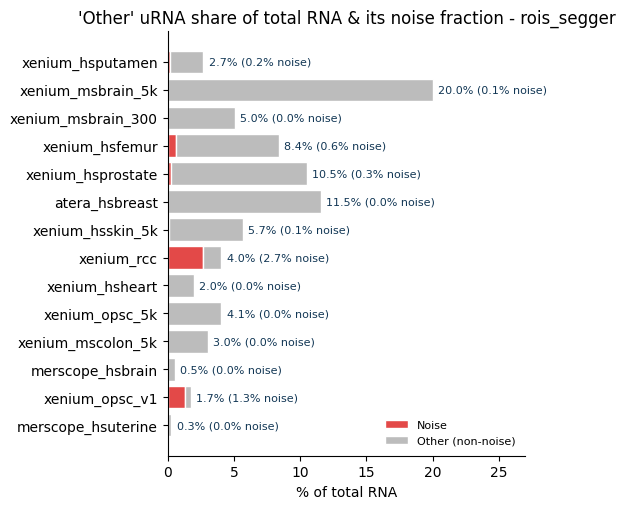

In [6]:
def plot_other_rna_context(df, xlabel, title, out_path):
    df = df.reindex(sample_order).dropna(subset=["proportion_of_total_rna_other"])

    total_pct = 100 * df["proportion_of_total_rna_other"]
    noise_pct = total_pct * df["proportion_of_other_urna_noise"]
    non_noise_pct = total_pct - noise_pct

    fig, ax = plt.subplots(figsize=(5.5, 0.3 * len(df) + 1))

    # Noise segment first (from 0): its length is then directly comparable across
    # bars. The non-noise segment stacks on top to complete the full context bar.
    ax.barh(df.index, noise_pct, color=noise_color, edgecolor="white", linewidth=1, label="Noise")
    ax.barh(df.index, non_noise_pct, left=noise_pct, color=other_color, edgecolor="white", linewidth=1, label="Other (non-noise)")

    for y, (total, noise) in enumerate(zip(total_pct, noise_pct)):
        ax.text(
            total + total_pct.max() * 0.02, y,
            f"{total:.1f}% ({noise:.1f}% noise)",
            va="center", ha="left", color="#123755", fontsize=8,
        )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlim(0, total_pct.max() * 1.35)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.legend(loc="lower right", frameon=False, fontsize=8)
    plt.tight_layout()
    plt.savefig(out_path, bbox_inches="tight")
    plt.show()

for seg in segmentations:
    if seg not in other_rna_noise_df.index.get_level_values("segmentation"):
        continue
    df = other_rna_noise_df.xs(seg, level="segmentation")
    plot_other_rna_context(
        df,
        xlabel="% of total RNA",
        title=f"'Other' uRNA share of total RNA & its noise fraction - {seg}",
        out_path=os.path.join(saving_path, f"{seg}_barplot_other_rna_context_and_noise.pdf"),
    )

## Proportion of genes explained by noise (other uRNA only), one plot per segmentation method

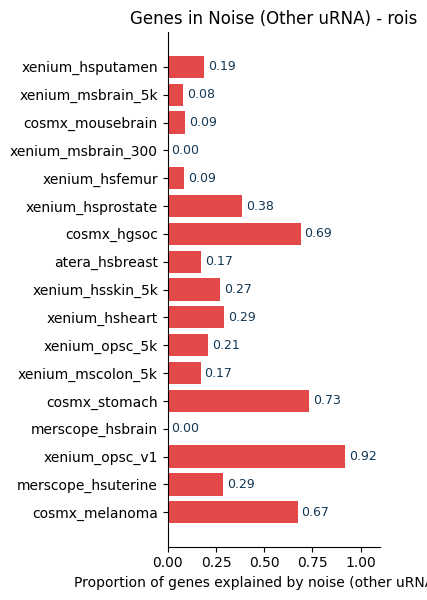

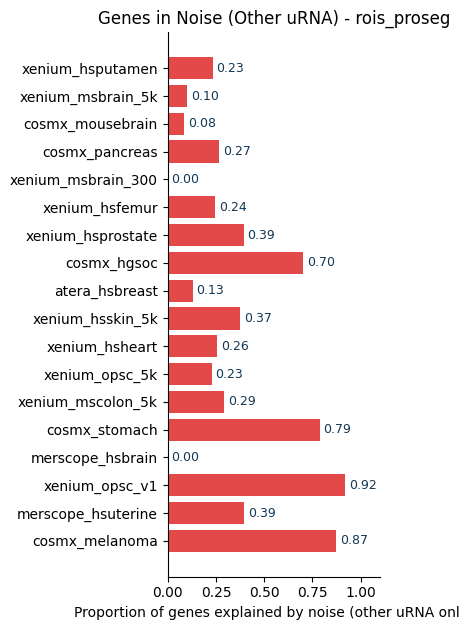

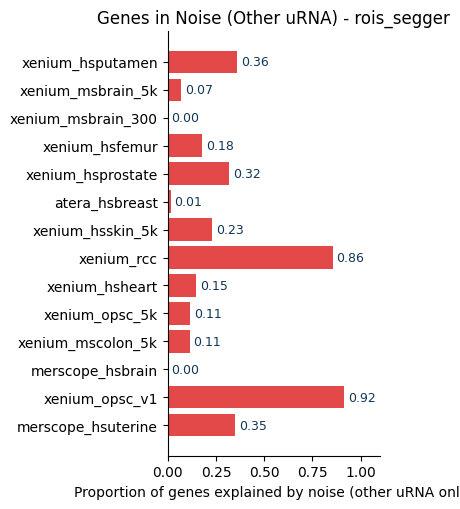

In [7]:
def plot_noise_proportion(noise_values, xlabel, title, out_path):
    noise_values = noise_values.reindex(sample_order).dropna()

    fig, ax = plt.subplots(figsize=(4, 0.3 * len(noise_values) + 1))
    bars = ax.barh(noise_values.index, noise_values, color=noise_color)

    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + 0.02, bar.get_y() + bar.get_height() / 2,
            f"{width:.2f}", va="center", ha="left", color="#123755", fontsize=9,
        )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlim(0, 1.1)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(out_path, bbox_inches="tight")
    plt.show()

for seg in segmentations:
    if seg not in other_rna_noise_df.index.get_level_values("segmentation"):
        continue
    values = other_rna_noise_df.xs(seg, level="segmentation")["proportion_of_other_genes_noise"]
    plot_noise_proportion(
        values,
        xlabel="Proportion of genes explained by noise (other uRNA only)",
        title=f"Genes in Noise (Other uRNA) - {seg}",
        out_path=os.path.join(saving_path, f"{seg}_barplot_genes_noise_other_urna.pdf"),
    )

## Compare noise levels across segmentation methods

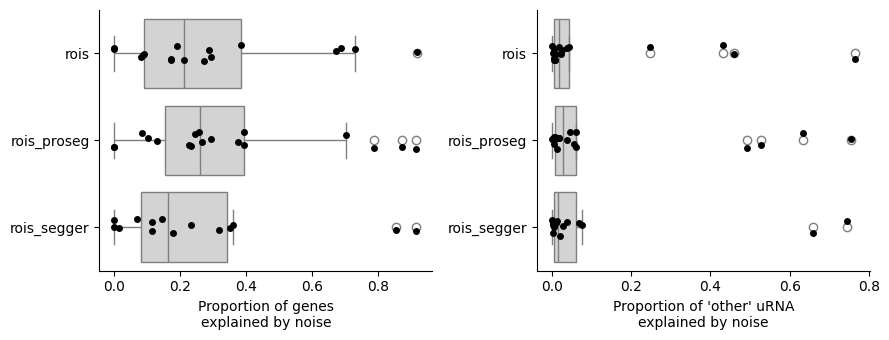

In [8]:
summary_df = other_rna_noise_df.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

sns.boxplot(data=summary_df, x="proportion_of_other_genes_noise", y="segmentation", color="lightgrey", ax=axes[0])
sns.stripplot(data=summary_df, x="proportion_of_other_genes_noise", y="segmentation", color="black", s=5, ax=axes[0])
axes[0].set_xlabel("Proportion of genes\nexplained by noise")
axes[0].set_ylabel("")

sns.boxplot(data=summary_df, x="proportion_of_other_urna_noise", y="segmentation", color="lightgrey", ax=axes[1])
sns.stripplot(data=summary_df, x="proportion_of_other_urna_noise", y="segmentation", color="black", s=5, ax=axes[1])
axes[1].set_xlabel("Proportion of 'other' uRNA\nexplained by noise")
axes[1].set_ylabel("")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(saving_path, "boxplot_other_urna_noise_by_segmentation.pdf"), bbox_inches="tight")
plt.show()

## Per-gene counts in the "other uRNA" pool: control probes vs. real genes (default segmentation)

One strip plot per dataset, default (`rois`) segmentation only. Each point is a gene; its position on the y-axis (log scale) is that gene's total transcript count within the "other unassigned RNA" pool. The two strips - control probes vs. real genes - show directly how much real-gene signal sits at or below the control-probe noise floor (dashed line = the Poisson noise baseline lambda used for significance testing).

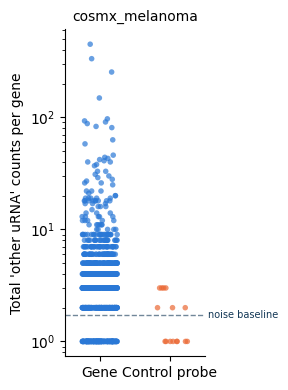

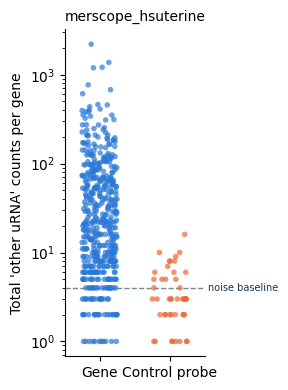

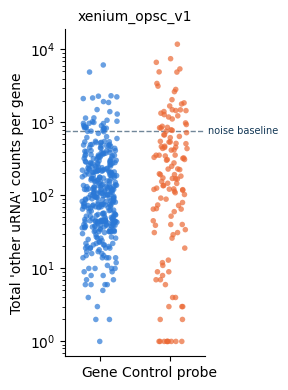

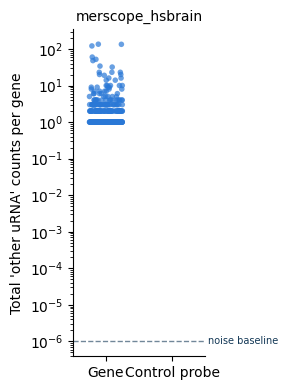

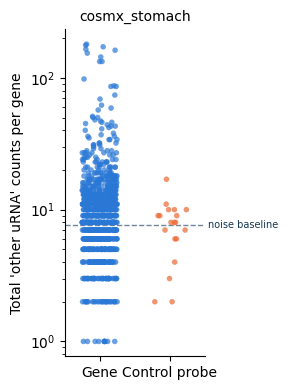

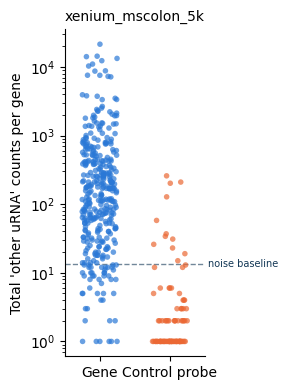

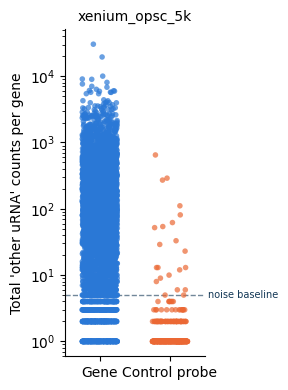

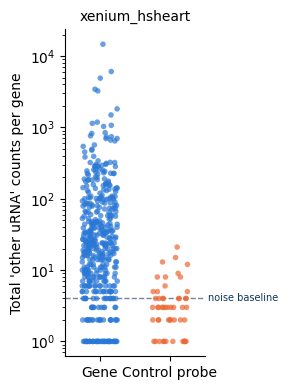

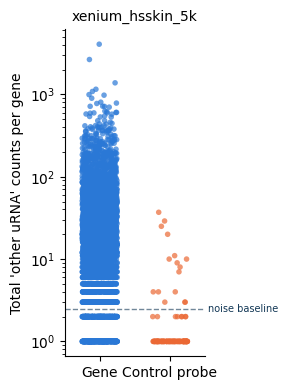

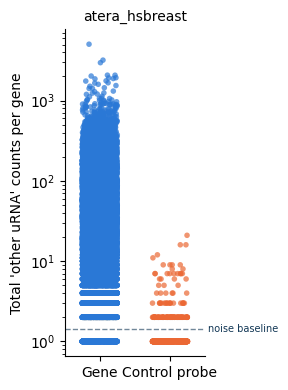

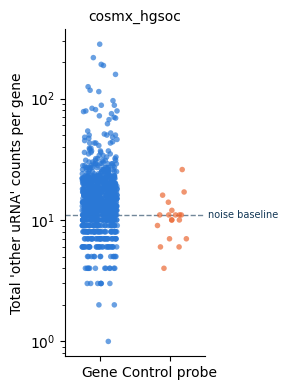

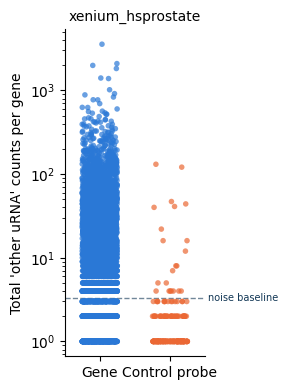

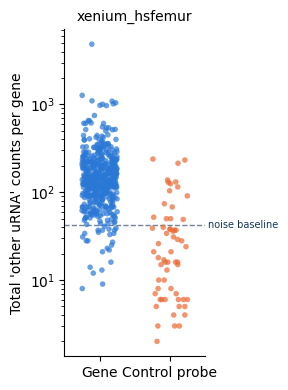

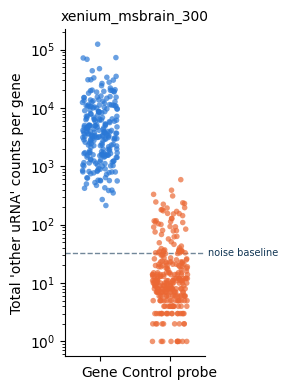

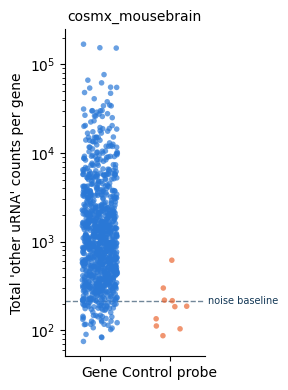

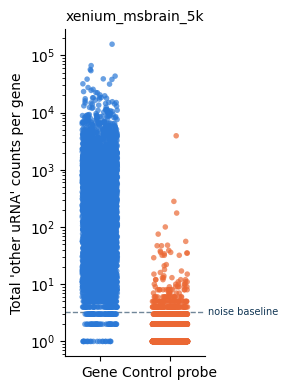

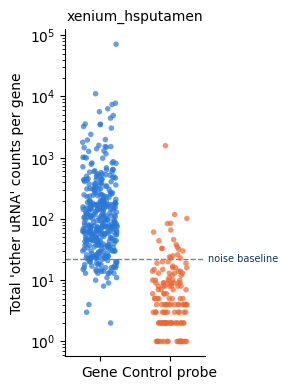

In [9]:
control_strip_dir = os.path.join(saving_path, "control_vs_gene_strips")
os.makedirs(control_strip_dir, exist_ok=True)

rois_noise_df = other_rna_noise_df.xs("rois", level="segmentation")

for sample in sample_order:
    if sample not in rois_gene_info:
        continue

    gene_info = rois_gene_info[sample].copy()
    gene_info["group"] = np.where(gene_info["is_control"], "Control probe", "Gene")

    fig, ax = plt.subplots(figsize=(3, 4))
    sns.stripplot(
        data=gene_info, x="group", y="count",
        hue="group", palette={"Gene": gene_color, "Control probe": control_color},
        order=["Gene", "Control probe"], hue_order=["Gene", "Control probe"],
        jitter=0.25, size=4, alpha=0.7, linewidth=0, legend=False, ax=ax,
    )

    lambda_noise = rois_noise_df.loc[sample, "lambda_noise"] if sample in rois_noise_df.index else None
    if lambda_noise and lambda_noise > 0:
        ax.axhline(lambda_noise, color="#123755", linestyle="--", linewidth=1, alpha=0.6)
        ax.text(
            1.02, lambda_noise, "noise baseline",
            transform=ax.get_yaxis_transform(),
            va="center", ha="left", fontsize=7, color="#123755",
        )

    ax.set_yscale("log")
    ax.set_xlabel("")
    ax.set_ylabel("Total 'other uRNA' counts per gene")
    ax.set_title(sample, fontsize=10)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.savefig(os.path.join(control_strip_dir, f"{sample}_control_vs_gene_stripplot.pdf"), bbox_inches="tight")
    plt.show()